# U-net for crack segmentation
### Assignment for M2MAS "Réseaux de Neurones profonds pour l'Apprentissage"

*References:*
 * U-Net: Convolutional Networks for Biomedical Image Segmentation, Olaf Ronneberger, Philipp Fischer, Thomas Brox, Medical Image Computing and Computer-Assisted Intervention (MICCAI), Springer, LNCS, Vol.9351: 234--241, 2015, available at [arXiv:1505.04597](http://arxiv.org/abs/1505.04597)
 * An 'All Terrain' Crack Detector Obtained by Deep Learning on Available Databases, Sébastien Drouyer, Image Processing On Line, 10 (2020), pp. 105–123. https://doi.org/10.5201/ipol.2020.282


### Modalities:
This assignment has to be send by email to bruno.galerne@univ-orleans.fr before Sunday March 1 2026, 23:59 with the name:

> ```NOM_PRENOM_M2MAS_202425_Unet_segmentation.ipynb```

Please use https://filesender.renater.fr/ if the file is larger than 5 MB.

Each question should be answered by providing a new section of the notebook (starting with a text cell ```# Question 1```) with all necessary code.
Code must be commented and introduced with a text cell. Results must be discussed in a text cell. In case of difficulty, you can also discuss errors in a text cell.


Each training of the neural network should be limited to 25 epochs. Note that the computation time will be arround 50 minutes on a T4 GPU.

### Questions:
First read and run the proposed notebook to get a first version of the network.

1. **Training pipeline:**
  
  1.A. **Dataset:** How many images are contained in each split (test, train, val)?
  
  1.B. **Dataloarders:** What is done by the dataloader function for each split ? What are the sizes of the output images ? Explain why we restrict images to be mutiple of 32 in width and height.

  1.C. **Training loss:** Give the exact equation of what is computed by the line
  
  ```
  loss = criterion(outputs, masks)
  ```

  You should introduce notations for tensors and specify the size of the involved tensors.
  
  1.D. **Performance evaluation:** Explain (in a text cell) what is computed by

```
valscores = test_performance(unet, valset)
testscores = test_performance(unet, testset)
```

2. **First training with early stopping:**
  * Improve the proposed code by defining a ```train```function with the following capacity:
    * Train the model for given number of epochs (25 epochs, but use only 2 epochs while developing the code...).
    * At each epoch, evaluate the performance on the validation set and retain the network with the best F1 score on validation set.
    * At each epoch, print the running time, epoch loss and F1 score on validation set.
    * At the end of training plot both the epoch loss for each epoch and the F1 score on validation set for each epoch.
  * When calling the train function:
    * Save the trained model to disk and load the model from disk (see https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-model-for-inference)
    * Download the model parameters and/or save them to your google drive for a reference.
    * Reload this models as ```unet_ref``` and check the reload is OK.
    * Evaluate and report its performance scores using ```test_performance``` on the testset.

3. **Efficiency of Unet architecture:**
  * Define a class ```Unet_without_connection``` that is similar to the Unet architecture but does not contain skip connections between the first and second part of the architecture. Chose the layer parameters so that intermediate features have the same size as for the original ```Unet```.
  * Train an instance of ```Unet_without_connection``` and compare with ```unet_ref```.

4. **Training with data augmentation:**
  * Explain in a few sentences the concept and interest of data augmentation.
  * Discuss a data augmentation strategy for the proposed dataset and implement it within ```class CRACK500(Dataset):```
  * Retrain the U-net with data augmentation (starting from a random initialization) for 25 epochs.
  * Save and reload the model as ```unet_data_aug```.
  * Compare with ```unet_ref``` regarding training loss and performance on test set.


# Provided notebook (not to be changed)
*This whole section should not be changed (except for the dataloader).
You may copy and change cells into your sections.
You can suppose that the cells of the provided notebook have been executed before your answers (no need to copy everything, only the changes)*

## Check that the notebook has an active GPU:
(otherwise go to Edit->Notebook properties ->...)

In [1]:
!nvidia-smi

Sun Mar  1 17:58:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   64C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Download CRACK500 datatset:
 * Reference work is here:
https://github.com/fyangneil/pavement-crack-detection

CRACK500

In [2]:
# Images:
# traincrop.zip
!gdown 1jsCzT4uDkLHel8ov1CfbvLXiQVy6KExT
# testcrop.zip
!gdown 1NwyJjbhEATg-5x8-hQqet3KuiIZOhXZu
# valcrop.zip
!gdown 1DboG3vmTjbZyzrUQSyqToZw_xCOaeNoE
# Download .txt files describing datasets:
# train.txt
!gdown 1f6kco4VRf47bBp0qtb57sePvoqA_xFZa
# test.txt
!gdown 1He8W5Zf32rrA-pCAopfV-MrX94jKU4nR
# val.txt
!gdown 1f4FG4pmB7bcRLeSGtNVCpjgAaMD5mrdm

Downloading...
From (original): https://drive.google.com/uc?id=1jsCzT4uDkLHel8ov1CfbvLXiQVy6KExT
From (redirected): https://drive.google.com/uc?id=1jsCzT4uDkLHel8ov1CfbvLXiQVy6KExT&confirm=t&uuid=3380ae04-7b13-45a2-9b15-d1a98a0aeb47
To: /content/traincrop.zip
100% 115M/115M [00:00<00:00, 226MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1NwyJjbhEATg-5x8-hQqet3KuiIZOhXZu
From (redirected): https://drive.google.com/uc?id=1NwyJjbhEATg-5x8-hQqet3KuiIZOhXZu&confirm=t&uuid=2972af80-8b45-4a00-ba9b-ea618c4a4d57
To: /content/testcrop.zip
100% 70.7M/70.7M [00:01<00:00, 47.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1DboG3vmTjbZyzrUQSyqToZw_xCOaeNoE
To: /content/valcrop.zip
100% 20.8M/20.8M [00:00<00:00, 211MB/s]
Downloading...
From: https://drive.google.com/uc?id=1f6kco4VRf47bBp0qtb57sePvoqA_xFZa
To: /content/train.txt
100% 143k/143k [00:00<00:00, 114MB/s]
Downloading...
From: https://drive.google.com/uc?id=1He8W5Zf32rrA-pCAopfV-MrX94jKU4nR
To: /content/test.

Unzip data (-q=quietly):

In [3]:
!unzip -q traincrop.zip
!unzip -q testcrop.zip
!unzip -q valcrop.zip
!ls

sample_data  testcrop.zip  traincrop	  train.txt  valcrop.zip
testcrop     test.txt	   traincrop.zip  valcrop    val.txt


In [4]:
!ls traincrop|wc -l


3792


(640, 360)


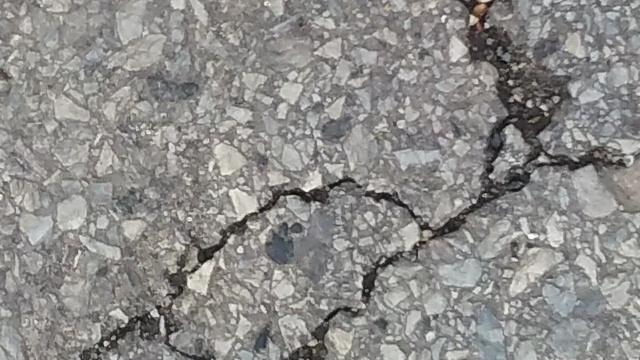

(640, 360)


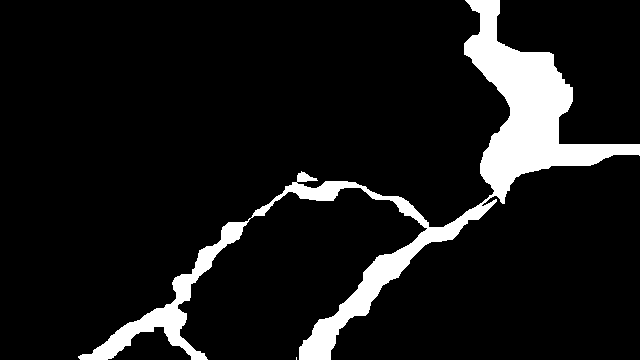

In [5]:
# Example of data:
from PIL import Image

imgpath='traincrop/20160328_153714_1281_721.jpg'
imgpil = Image.open(imgpath)
print(imgpil.size)
display(imgpil)
imgpath='traincrop/20160328_153714_1281_721.png'
imgpil = Image.open(imgpath)
print(imgpil.size)
display(imgpil)

#PyTorch Dataloaders:

Create a data loader for the train, test, val datasets.
We follow mostly:
WRITING CUSTOM DATASETS, DATALOADERS AND TRANSFORMS
https://pytorch.org/tutorials/beginner/data_loading_tutorial.html


In [6]:
import torch
from torchvision import transforms, utils
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
import time

from PIL import Image
import torchvision.transforms.functional as TF
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [7]:
# image lists are opened using panda:
trainlist = pd.read_csv('train.txt', sep=' ',header=None)
#print(trainlist)
print(trainlist.shape)
print(len(trainlist))
print(trainlist.iloc[1700,0]) # image filename
print(trainlist.iloc[1700,1]) # mask filename


(1896, 2)
1896
traincrop/20160405_171336_641_721.jpg
traincrop/20160405_171336_641_721.png


In [8]:

class CRACK500(Dataset):
    """CRACK500 dataset."""

    def __init__(self, txt_file, root_dir, train=False, data_augmentation=False):
        """
        Args:
            txt_file (string): Path to the txt file list of image paths (eg train.txt, test.txt, val.txt).
            root_dir (string): Parent directory for the directory with all the images.
            train (boolean): True for training dataset (crop images to have size 256x256, otherwise get full image)
            data_augmentation (boolean): True for using data_augmentation during training
        """
        self.imgslist = pd.read_csv(txt_file, sep=' ',header=None)
        self.root_dir = root_dir
        self.train = train
        self.data_augmentation = data_augmentation
    def __len__(self):
        return len(self.imgslist)

    def __getitem__(self, idx):
        # get image and mask paths
        img_name = os.path.join(self.root_dir, self.imgslist.iloc[idx, 0])
        mask_name = os.path.join(self.root_dir, self.imgslist.iloc[idx, 1])

        # open images using PIL and apply transform list:
        image = Image.open(img_name)
        image = transforms.ToTensor()(image)
        image = transforms.Grayscale()(image)
        if image.shape[1]>image.shape[2]:
          image = image.transpose(1,2)
        image = transforms.Normalize(0.5, 0.5)(image) # shape 1 x w x h

        # open mask binary image using PIL:
        mask = Image.open(mask_name)
        mask = transforms.ToTensor()(mask)
        if mask.shape[1]>mask.shape[2]:
          mask = mask.transpose(1,2)
        mask = mask.long().squeeze() # shape w x h

        if self.train: #get a subimage of size 256x256:
          if self.data_augmentation:

            # TODO:
            print('NOT IMPLEMENTED YET')

          else:
            # crop center 256x256:
            h,w = mask.shape
            c1 = (h-256)//2 # (c1,c2) is top-left corner
            c2 = (w-256)//2
            image = image[:,c1:(c1+256),c2:(c2+256)]
            mask = mask[c1:(c1+256),c2:(c2+256)]
        else:
          # full image cropped to be multiple of 32:
          h,w = mask.shape
          nh = (h//32)*32
          nw = (w//32)*32
          image = image[:,:nh,:nw]
          mask = mask[:nh,:nw]

        sample = [image, mask]
        return sample


## Test datasets:

train
torch.Size([1, 256, 256])
torch.float32
torch.Size([256, 256])
torch.int64


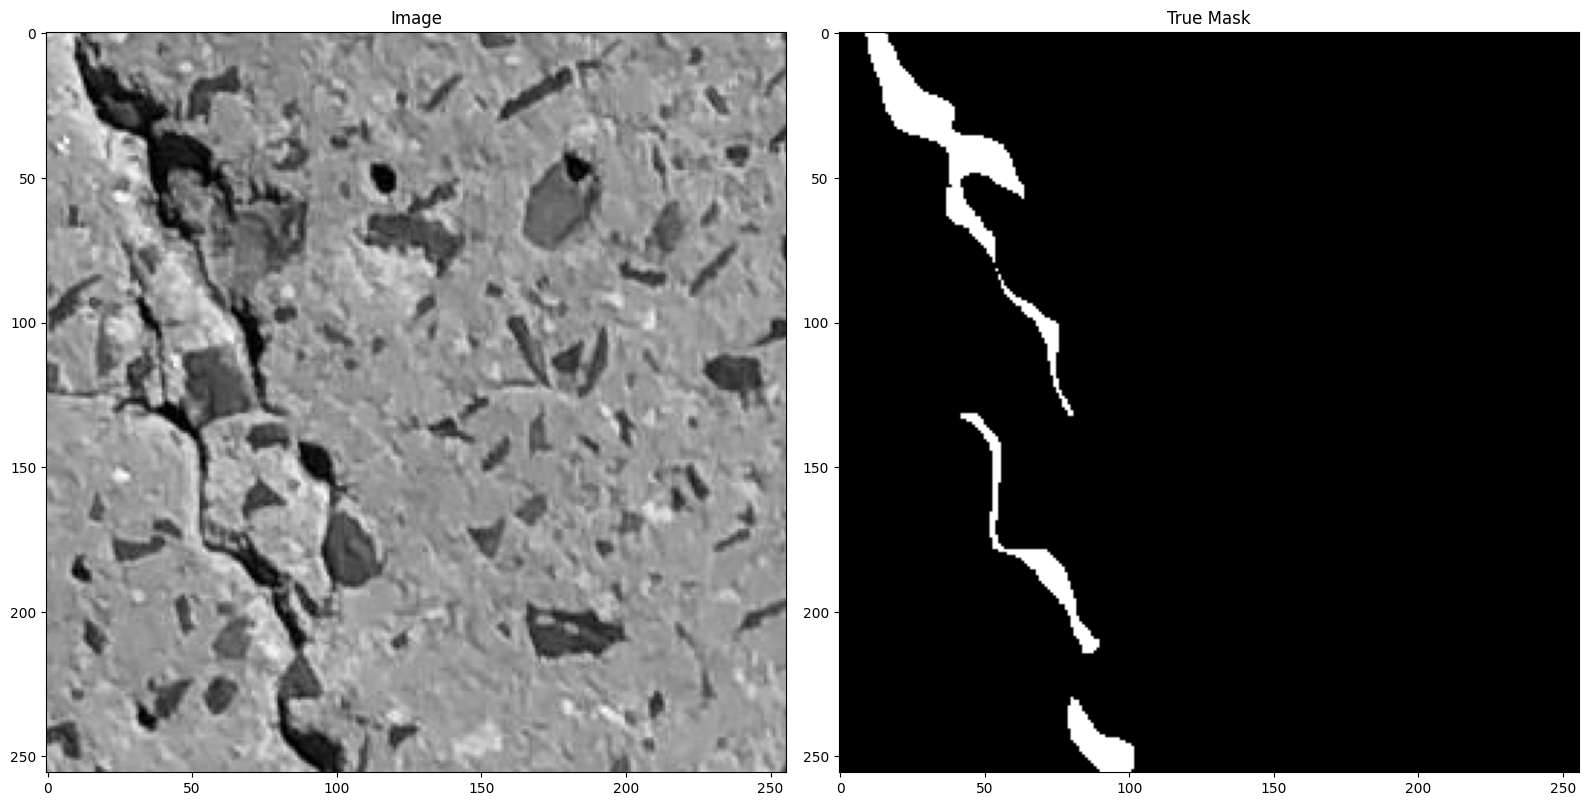

test
torch.Size([1, 352, 640])
torch.float32
torch.Size([352, 640])
torch.int64


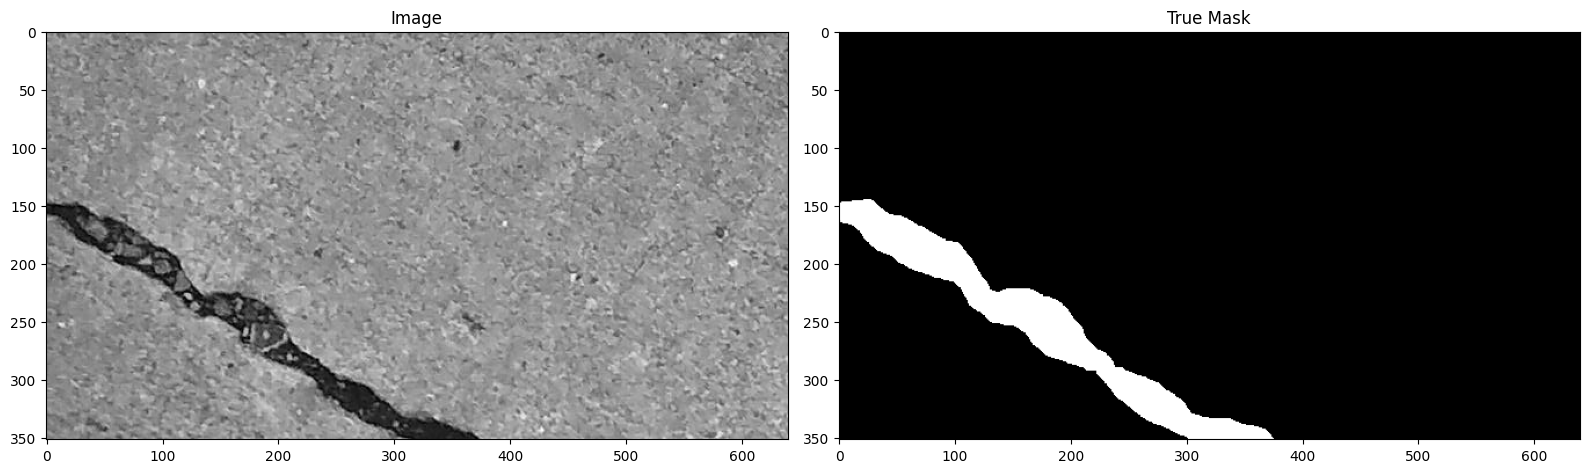

val
torch.Size([1, 352, 640])
torch.float32
torch.Size([352, 640])
torch.int64


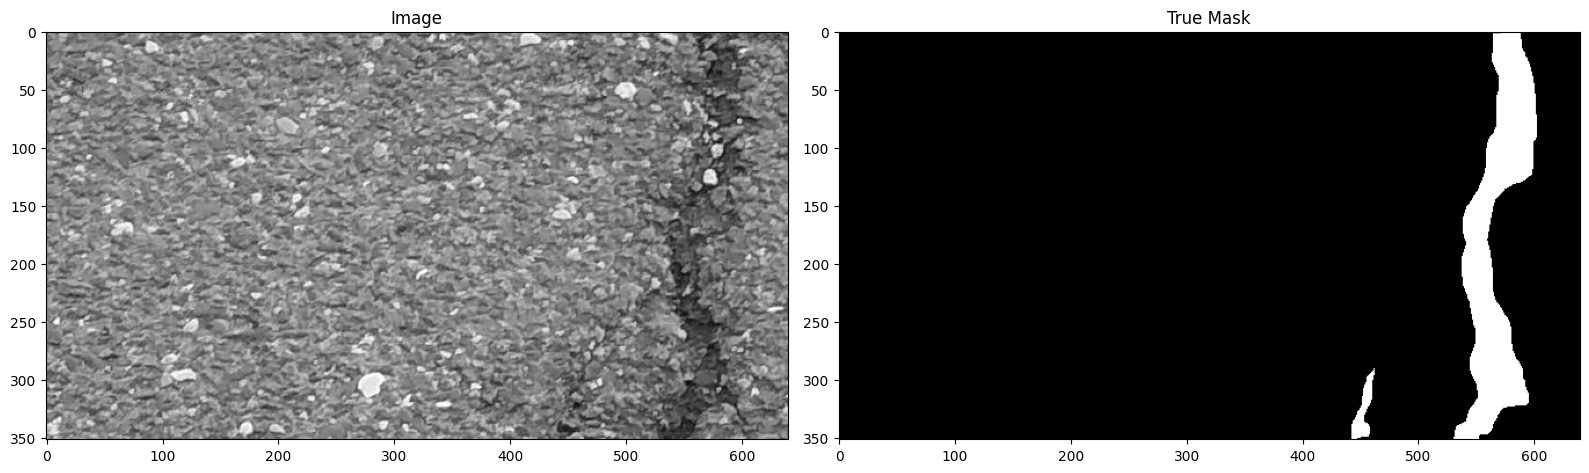

In [9]:
trainset = CRACK500(txt_file='train.txt', root_dir='', train=True, data_augmentation=False)
image, mask = trainset[100]
print('train')
print(image.size())
print(image.dtype)
print(mask.size())
print(mask.dtype)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].imshow(image.squeeze(), cmap=plt.cm.gray)
ax[0].set_title("Image")
ax[1].imshow(mask, cmap=plt.cm.gray)
ax[1].set_title("True Mask")
fig.tight_layout()
plt.show()


testset = CRACK500(txt_file='test.txt', root_dir='', train=False, data_augmentation=False)
image, mask = testset[0]
print('test')
print(image.size())
print(image.dtype)
print(mask.size())
print(mask.dtype)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].imshow(image.squeeze(), cmap=plt.cm.gray)
ax[0].set_title("Image")
ax[1].imshow(mask, cmap=plt.cm.gray)
ax[1].set_title("True Mask")
fig.tight_layout()
plt.show()

valset = CRACK500(txt_file='val.txt', root_dir='', train=False, data_augmentation=False)
image, mask = valset[21]
print('val')
print(image.size())
print(image.dtype)
print(mask.size())
print(mask.dtype)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].imshow(image.squeeze(), cmap=plt.cm.gray)
ax[0].set_title("Image")
ax[1].imshow(mask, cmap=plt.cm.gray)
ax[1].set_title("True Mask")
fig.tight_layout()
plt.show()



In [10]:
# check full dataset: (sanity check, useful only to check that all images are OK)
for k, dataset in enumerate([trainset, testset, valset]):
  print(['DATASET: ', k])
  for i in range(len(dataset)):
    image, mask = dataset[i]
    if k==0:
      if image.shape[1] != 256 or image.shape[2] != 256:
        print([k,i,image.shape])
    else:
      if image.shape[1] != 352 or image.shape[2] != 640:
        print([k,i,image.shape])

['DATASET: ', 0]
['DATASET: ', 1]
['DATASET: ', 2]
[2, 331, torch.Size([1, 480, 640])]
[2, 332, torch.Size([1, 480, 640])]
[2, 333, torch.Size([1, 480, 640])]
[2, 334, torch.Size([1, 480, 640])]
[2, 335, torch.Size([1, 480, 640])]
[2, 336, torch.Size([1, 480, 640])]
[2, 337, torch.Size([1, 480, 640])]
[2, 338, torch.Size([1, 480, 640])]
[2, 339, torch.Size([1, 480, 640])]
[2, 340, torch.Size([1, 480, 640])]
[2, 341, torch.Size([1, 480, 640])]
[2, 342, torch.Size([1, 480, 640])]
[2, 343, torch.Size([1, 480, 640])]
[2, 344, torch.Size([1, 480, 640])]
[2, 345, torch.Size([1, 480, 640])]
[2, 346, torch.Size([1, 480, 640])]
[2, 347, torch.Size([1, 480, 640])]


## U-net version with same size (as in IPOL paper)


In [11]:
#double 3x3 convolution
def dual_conv(in_channel, out_channel):
    conv = nn.Sequential(
        nn.Conv2d(in_channel, out_channel, kernel_size=3,padding=1,padding_mode='reflect'),
        nn.ReLU(inplace= True),
        nn.Conv2d(out_channel, out_channel, kernel_size=3,padding=1,padding_mode='reflect'),
        nn.ReLU(inplace= True),
    )
    return conv

class Unet(nn.Module):
    def __init__(self):
        super(Unet, self).__init__()

        # Left side (contracting path)
        self.dwn_conv1 = dual_conv(1, 64)
        self.dwn_conv2 = dual_conv(64, 128)
        self.dwn_conv3 = dual_conv(128, 256)
        self.dwn_conv4 = dual_conv(256, 512)
        self.dwn_conv5 = dual_conv(512, 1024)
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)

        #Right side  (expnsion path)
        #transpose convolution is used shown as green arrow in architecture image
        self.trans1 = nn.ConvTranspose2d(1024,512, kernel_size=2, stride= 2)
        self.up_conv1 = dual_conv(1024,512)
        self.trans2 = nn.ConvTranspose2d(512,256, kernel_size=2, stride= 2)
        self.up_conv2 = dual_conv(512,256)
        self.trans3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride= 2)
        self.up_conv3 = dual_conv(256,128)
        self.trans4 = nn.ConvTranspose2d(128,64, kernel_size=2, stride= 2)
        self.up_conv4 = dual_conv(128,64)

        #output layer
        self.out = nn.Conv2d(64, 2, kernel_size=1)

    def forward(self, image):

        #forward pass for Left side
        x1 = self.dwn_conv1(image)
        x2 = self.maxpool(x1)
        x3 = self.dwn_conv2(x2)
        x4 = self.maxpool(x3)
        x5 = self.dwn_conv3(x4)
        x6 = self.maxpool(x5)
        x7 = self.dwn_conv4(x6)
        x8 = self.maxpool(x7)
        x9 = self.dwn_conv5(x8)

        #forward pass for Right side
        x = self.trans1(x9)
        x = self.up_conv1(torch.cat([x,x7], 1))

        x = self.trans2(x)
        x = self.up_conv2(torch.cat([x,x5], 1))

        x = self.trans3(x)
        x = self.up_conv3(torch.cat([x,x3], 1))

        x = self.trans4(x)
        x = self.up_conv4(torch.cat([x,x1], 1))

        x = self.out(x)

        return x

unet = Unet().to(device)


## Test of untrained Unet:

In [12]:
# Apply Unet and check sizes:
image, mask = trainset[3]
with torch.no_grad():
  out=unet(torch.unsqueeze(image.to(device),0))
  print('output size: ', out.size())
  print('mask size: ',mask.size())
  criterion = nn.CrossEntropyLoss()
  loss = criterion(out, torch.unsqueeze(mask.to(device),0))
  print(loss.item())

output size:  torch.Size([1, 2, 256, 256])
mask size:  torch.Size([256, 256])
0.6693019866943359


#Training of Unet:


In [13]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(unet.parameters())


##Define data loader for batch training:

In [14]:
dataloader = DataLoader(trainset, batch_size=20, shuffle=True, num_workers=2)
n_train = len(trainset)

In [15]:
iter_info = 100
since = time.time()
for epoch in range(2):
  since_epoch = time.time()
  running_loss = 0.0
  epoch_loss = 0.0
  for i, data in enumerate(dataloader, 0):
    # get the inputs; data is a list of [inputs, labels]
    images = data[0].to(device)
    masks = data[1].to(device)

    # zero the parameter gradients
    optimizer.zero_grad()

    # forward + backward + optimize
    outputs = unet(images)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    # print statistics
    running_loss += loss.item()
    epoch_loss += loss.item()
    if i % iter_info == (iter_info-1):    # print every iter_info mini-batches
      print('[%d, %5d] loss: %.3f' %
        (epoch + 1, i + 1, running_loss / iter_info))
      running_loss = 0.0
  time_elapsed_epoch = time.time() - since_epoch
  print('Epoch completed in {:.0f}m {:.0f}s'.format(
        time_elapsed_epoch // 60, time_elapsed_epoch % 60))
  print('Epoch loss: %.3f' % (epoch_loss / n_train))

print('Finished Training')
time_elapsed = time.time() - since
print('Training completed in {:.0f}m {:.0f}s'.format(
        time_elapsed // 60, time_elapsed % 60))


Epoch completed in 1m 57s
Epoch loss: 0.014
Epoch completed in 1m 58s
Epoch loss: 0.008
Finished Training
Training completed in 3m 55s


#Visualize some prediction (on cropped val image to be improved for performance evaluation):
Images size must be multiple of 32.






torch.Size([1, 352, 640]) torch.Size([352, 640])
torch.Size([1, 352, 640]) torch.Size([352, 640])


<Figure size 640x480 with 0 Axes>

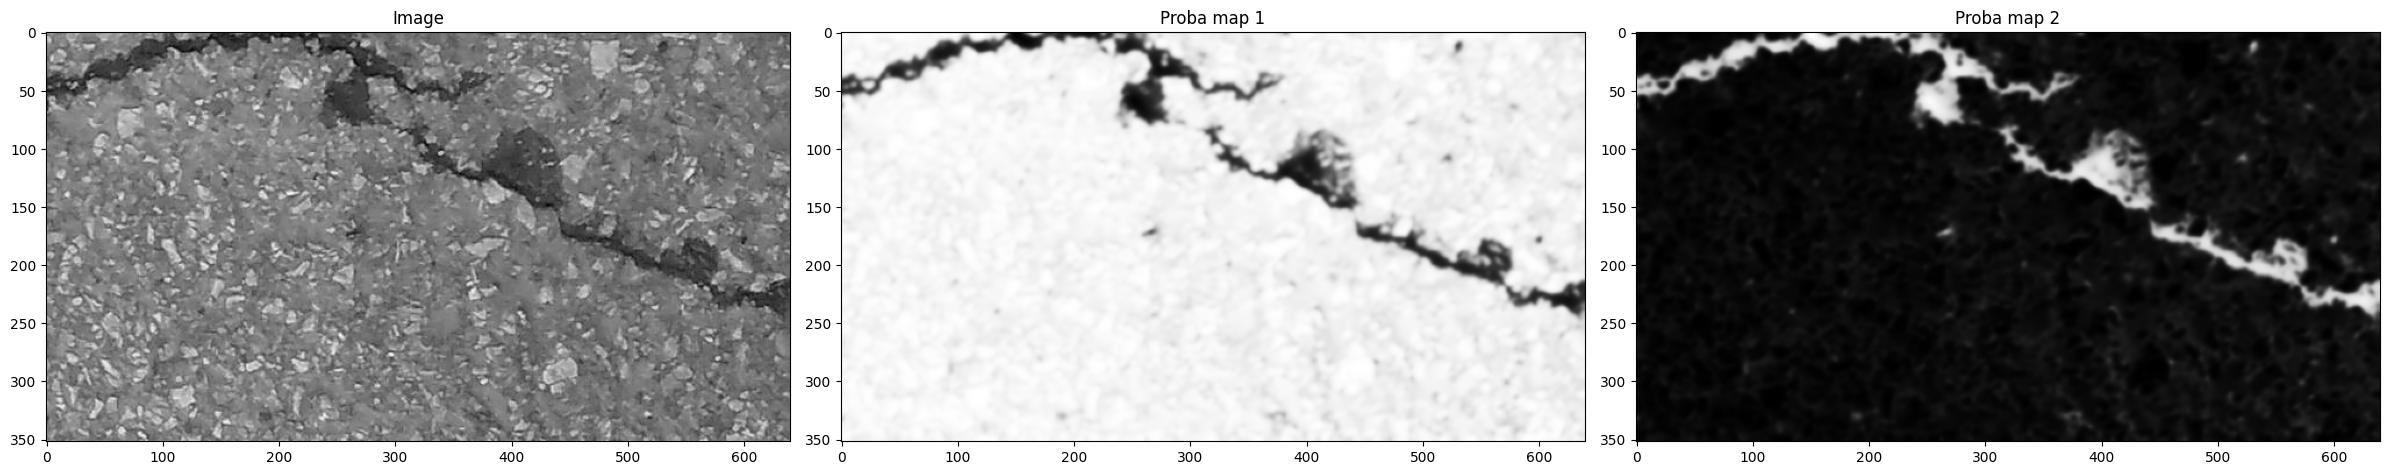

<Figure size 640x480 with 0 Axes>

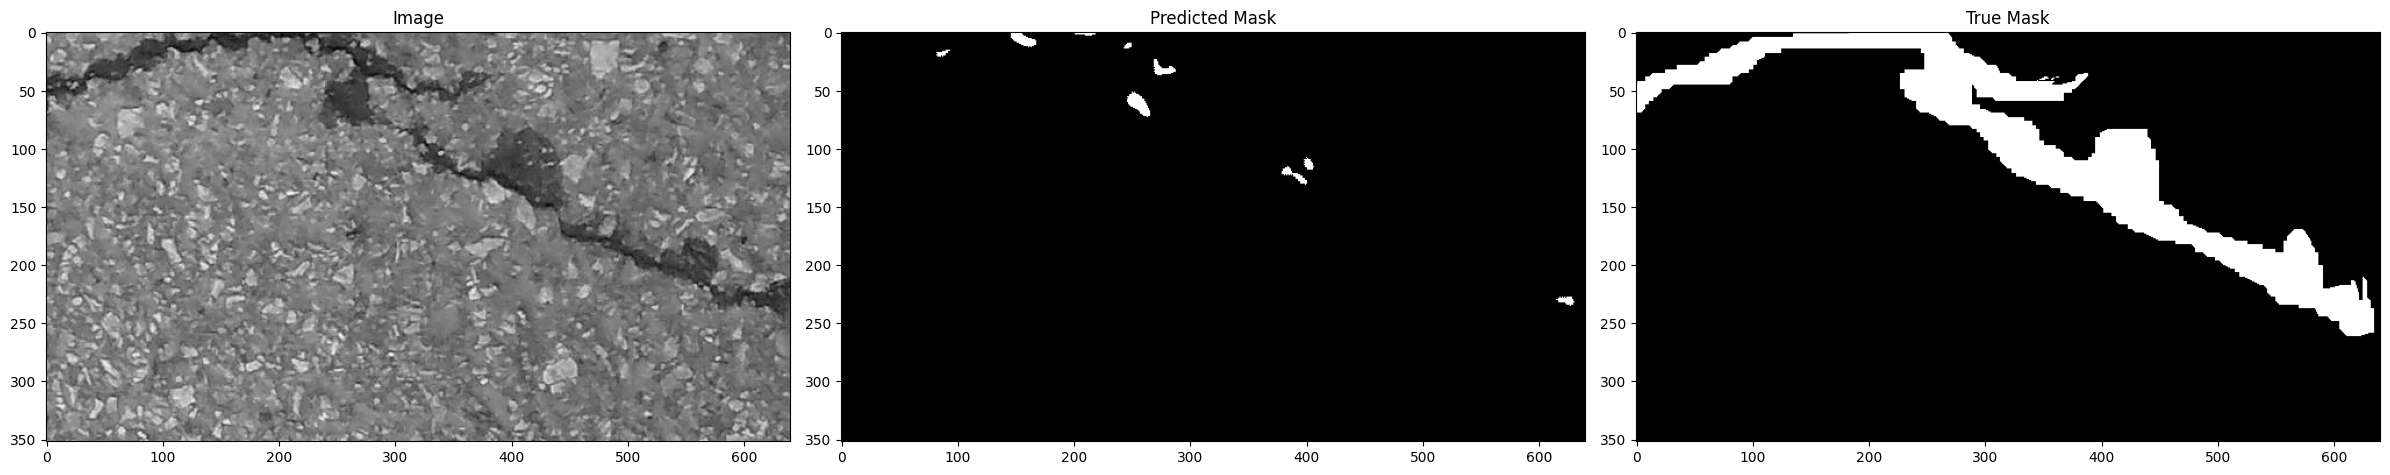

In [16]:

i = np.random.randint(len(valset))
image, mask = valset[i]
print(image.size(), mask.size())
h,w = mask.size()
nh = (h//32)*32
nw = (w//32)*32
image = image[:,:nh,:nw]
mask = mask[:nh,:nw]
print(image.size(), mask.size())

with torch.no_grad():
  out = unet(torch.unsqueeze(image.to(device),0))
  predprob = F.softmax(out,dim=1).to('cpu')
predprob1 = predprob[0,0,:,:].squeeze()
predprob2 = predprob[0,1,:,:].squeeze()
predmask = torch.argmax(out.squeeze(), dim=0).to('cpu')

plt.figure();

fig, ax = plt.subplots(1, 3, figsize=(24, 8))
ax[0].imshow(image.squeeze(), cmap=plt.cm.gray)
ax[0].set_title("Image")
ax[1].imshow(predprob1, cmap=plt.cm.gray)
ax[1].set_title("Proba map 1")
ax[2].imshow(predprob2, cmap=plt.cm.gray)
ax[2].set_title("Proba map 2")
fig.tight_layout()
plt.show();

plt.figure()

fig, ax = plt.subplots(1, 3, figsize=(24, 8))
ax[0].imshow(image.squeeze(), cmap=plt.cm.gray)
ax[0].set_title("Image")
ax[1].imshow(predmask, cmap=plt.cm.gray)
ax[1].set_title("Predicted Mask")
ax[2].imshow(mask, cmap=plt.cm.gray)
ax[2].set_title("True Mask")
fig.tight_layout()
plt.show();



## Performance evaluation:

In [17]:
def test_performance(unet, dataset):
  tp_count = 0
  tn_count = 0
  fp_count = 0
  fn_count = 0
  with torch.no_grad():
    for i, data in enumerate(dataset):
      image = data[0]
      mask = data[1]
      h,w = mask.size()
      nh = (h//32)*32
      nw = (w//32)*32
      image = image[:,:nh,:nw].to(device)
      mask = mask[:nh,:nw].to(device)
      out = unet(torch.unsqueeze(image,0))
      predmask = torch.argmax(out.squeeze(), dim=0)
      # count:
      tp = torch.sum(predmask*mask)
      fp = torch.sum(predmask*(1.-mask))
      tn = torch.sum((1-predmask)*(1.-mask))
      fn = torch.sum((1-predmask)*mask)
      if not (tp+fp+tn+fn == nh*nw):
        print('counting inconstancy')
      tp_count = tp_count + tp
      tn_count = tn_count + tn
      fp_count = fp_count + fp
      fn_count = fn_count + fn
      if i%100==99:
        print('test_performance: Image ', i, ' / ', len(dataset))
    print(tp_count.item(), tn_count.item(), fp_count.item(), fn_count.item())
    precision = (tp_count/(tp_count+fp_count)).to('cpu').item()
    recall = (tp_count/(tp_count+fn_count)).to('cpu').item()
    F1score =  2. * precision * recall / (precision + recall)
    return([precision, recall, F1score])

valscores = test_performance(unet, valset)
for name, val in zip(["precision", "recall", "F1score"], valscores):
  print(name, '{:.4f}'.format(val))

test_performance: Image  99  /  348
test_performance: Image  199  /  348
test_performance: Image  299  /  348
1017077 75046072.0 232636.0 3494283
precision 0.8138
recall 0.2254
F1score 0.3531


#Question 1  
## 1.A

- on constate que dans le dossier traincrop, valcrop et testcrop il y a respectivement 3792, 696 et 2248 éléments.

In [18]:
!ls traincrop|wc -l
!ls valcrop|wc -l
!ls testcrop|wc -l



3792
696
2248


- Cependant, en regardant dans test.txt, train.txt et val.txt , on se rend compte qu'on a plutot une première colonne qui correspond aux images et une deuxieme qui correspond aux masks.



In [19]:
## Pour Train

# image lists are opened using panda:
trainlist = pd.read_csv('train.txt', sep=' ',header=None)
#print(trainlist)
print(trainlist.shape)
print(len(trainlist))
print(trainlist.iloc[1700,0]) # image filename
print(trainlist.iloc[1700,1]) # mask filename


(1896, 2)
1896
traincrop/20160405_171336_641_721.jpg
traincrop/20160405_171336_641_721.png


In [20]:
## Pour Test

# image lists are opened using panda:
testlist = pd.read_csv('test.txt', sep=' ',header=None)
#print(trainlist)
print(testlist.shape)
print(len(testlist))
print(testlist.iloc[1100,0]) # image filename
print(testlist.iloc[1100,1]) # mask filename


(1124, 2)
1124
testcrop/20160330_164743_1921_361.jpg
testcrop/20160330_164743_1921_361.png


In [21]:
## Pour val

# image lists are opened using panda:
vallist = pd.read_csv('val.txt', sep=' ',header=None)
#print(trainlist)
print(vallist.shape)
print(len(vallist))
print(vallist.iloc[300,0]) # image filename
print(vallist.iloc[300,1]) # mask filename


(348, 2)
348
valcrop/20160402_151054_1_361.jpg
valcrop/20160402_151054_1_361.png


Au final on peut dire que:
- Dans Train, il y a 1896 images et 1896 masks
- Dans Test, il y a 1124 images et 1124 masks
- Dans Val, il y a 348 images et 348 masks

## 1.B  

- Pour Train, le dataloader prends un batch de 20 images et 20 masks, mélange l'ordre pour chaque epoch et l'envoie au réseau.   

- Pour Val et Test, le dataloader prend un batch de 20 images et 20 masks et l'envoie au réseau.



Dans ``` def __getitem__ ``` :   

- en Train, les sorties sont de taille 256x256
- en Val et Test, les sorties sont cropped de sorte à avoir une dimension multiple de 32.

La largeur et la hauteur de l'image doivent être des multiples de 32 car:
- Lors de la "descente" dans un U-net, l'image passe par plusieurs couches (généralement 5; ici il n'y a que 4 maxpooling ) de maxpooling qui divise sa taille par 2; et 2x2x2x2x2 = 32.
- Egalement, si la taille n'est pas un multiple de 32, une division entière est faite et lors de la "remontée" en remultipliant par 2, si la taille ne correspond pas; il y a erreur .

## 1.D  

Ici, ces codes calculent la performance du U-net sur les ensembles de validation et de test.
Précisément, pour commencer:   
 Dans la fonction test_performance, ``` with torch.no_grad() ``` désactive le calcul du gradient pour que le modèle n'apprrenne pas sur ces données (de test et de validation).  
 Ensuite, pour chaque image envoyée au U-net, il nous renvoie les probabilités pour que chaque pixel soit un fond ou une fissure. Avec ```` predmask = torch.argmax(out.squeeze(), dim=0) ```` on a le mask que le modèle prédit. Après, il y a le calcul de true positive, true negative, fp et fn avec ```` tp = torch.sum(predmask*mask)
      fp = torch.sum(predmask*(1.-mask))
      tn = torch.sum((1-predmask)*(1.-mask))
      fn = torch.sum((1-predmask)*mask) ```` .  
 Enfin, le calcul de la précision, du f1score et du Recall.




#Question 2


Ici, pour la fonction train, je me suis basée sur la logique de la fonction train_model du projet d'avant ainsi que du bout de code qui se trouve à la section **Define data loader for batch training:** .  

Pour chaque epoch, on fait un entrainement et une évaluation. Pour l'entrainement, on utilise le code de la section évoquer tout à l'heure et pour l'évaluation, on calcul la loss moyenne sur l'epoch et la fonction test_performance , on calcul le F1 score.
A la fin de chaque epoch, on sauvegarde le meilleur modèle en regardant si le score F1 de l'epoch est supérieur au meilleur; si oui on retient le modèle actuel et ses paramètres.


In [22]:
import copy

def train(unet,dataloader,valset, num_epochs=25):
    since = time.time()

    # définition des paramètres
    best_model_wts = copy.deepcopy(unet.state_dict())
    best_f1 = 0.0

    #les paramètres pour le dessin
    his_los = []
    his_f1 = []

    #on commence l'iteration sur les epoch
    for epoch in range(num_epochs):
      # affichage
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)
        since_epoch = time.time()
        epoch_loss = 0.0

        unet.train() # on le met en mode train

        ## entrainement

        for i, data in enumerate(dataloader, 0):
            # get the inputs; data is a list of [inputs, masks]
            images = data[0].to(device)
            masks = data[1].to(device)

            optimizer.zero_grad()  # zero the parameter gradient
            outputs = unet(images)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        ## evaluation
        unet.eval() #en mode validation

        la_loss = epoch_loss/len(dataloader) # la loss moyenne par batch dans le dataloader
        his_los.append(la_loss) # on ajoute la loss pour pouvoir fair le dessin

        valscore = test_performance(unet,valset) #test_performance pour calculer F1 score, recall et précision
        f1_now = valscore[2] #pour le f1
        his_f1.append(f1_now) #on ajoute le f1 calculé pour pouvoir faire le dessin

        ## affichage du temps, de la loss et de F1 score
        time_elapsed_epoch = time.time() - since_epoch
        print('Epoch completed in {:.0f}m {:.0f}s'.format(time_elapsed_epoch // 60, time_elapsed_epoch % 60))
        print('f1 score: {:.4f}'.format(f1_now))
        print('loss: {:.4f}'.format(la_loss))

        ## pour selectionner celui avec le meilleur score
        if f1_now > best_f1:
            best_f1 = f1_now
            best_model_wts = copy.deepcopy(unet.state_dict())
            torch.save(unet.state_dict(),'best_unet.pth')


    unet.load_state_dict(best_model_wts)
    plt.figure()
    plt.subplot(1, 2, 1)
    plt.plot(his_los, label='Loss', color='red')
    plt.title('Training Loss')
    plt.subplot(1, 2, 2)
    plt.plot(his_f1, label='F1 Score', color='blue')
    plt.title('F1 Score')
    plt.show()

    return unet

entraînement
Epoch 0/1
----------
test_performance: Image  99  /  348
test_performance: Image  199  /  348
test_performance: Image  299  /  348
2093378 74410368.0 868359.0 2417982
Epoch completed in 2m 29s
f1 score: 0.5602
loss: 0.1397
Epoch 1/1
----------
test_performance: Image  99  /  348
test_performance: Image  199  /  348
test_performance: Image  299  /  348
1613030 74851968.0 426747.0 2898330
Epoch completed in 2m 28s
f1 score: 0.4924
loss: 0.1293


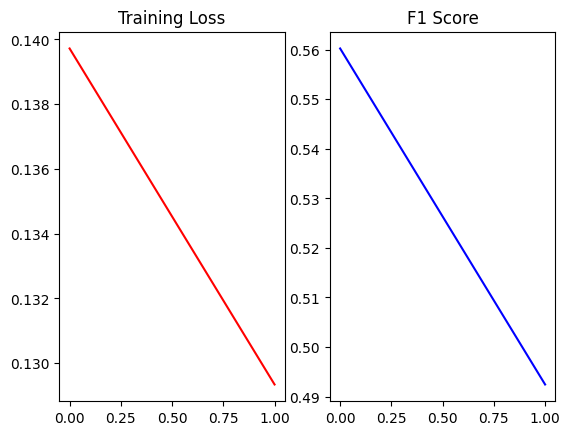


 Création de unet_ref 
 OK !

 Évaluation sur le testset...
test_performance: Image  99  /  1124
test_performance: Image  199  /  1124
test_performance: Image  299  /  1124
test_performance: Image  399  /  1124
test_performance: Image  499  /  1124
test_performance: Image  599  /  1124
test_performance: Image  699  /  1124
test_performance: Image  799  /  1124
test_performance: Image  899  /  1124
test_performance: Image  999  /  1124
test_performance: Image  1099  /  1124
6309426 234052544.0 4998542.0 7854059
Résultats de unet_ref 
Précision : 0.5580
F1-Score  : 0.4954


In [23]:
print("entraînement")

unet = train(unet, dataloader, valset, num_epochs=2) ##

print("\n Création de unet_ref ")

unet_ref = Unet().to(device)
unet_ref.load_state_dict(torch.load('best_unet.pth'))
print(" OK !")

print("\n Évaluation sur le testset...")
testscores = test_performance(unet_ref, testset)

print("Résultats de unet_ref ")
print("Précision : {:.4f}".format(testscores[0]))
print("F1-Score  : {:.4f}".format(testscores[2]))

Après l'utilisation de  la fonction train, on constatte que :

- lors de l'entrainement sur 2 épochs, on a:   

l'epoch 0 qui a un f1 score: 0.5602 et une loss:  0.1397, ce qui est assez encourageant. A l'epoch 1, la loss a diminué et est passé à 0.1293 et le f1 score a également diminué;  f1 score: 0.4924. le modèle à l'epoch 1 est moins bon en terme de F1 Score que le précédent; même si la loss a diminué.

- lors de l'évaluation, le modèle chargé est celui de l'epoch 0. Ce modèle a été utilisé sur les images de test et a eu F1-Score  : 0.4954. Ces résultats sont interessants en considérant le fait qu'il n ' y a eu que 2 epochs pour l'entrainement.

In [24]:
from google.colab import files

files.download('best_unet.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Question 3


Ici, il est demandé de définir un réseau U-net mais sans le "lien" entre la partie descente et la partie ascendante du U.
Ce lien étant fait par la commande ``` torch.cat```, on va  enlever celle ci et réajuster pour que les entrées et sorties correspondent.

In [25]:
#double 3x3 convolution
def dual_conv(in_channel, out_channel):
    conv = nn.Sequential(
        nn.Conv2d(in_channel, out_channel, kernel_size=3,padding=1,padding_mode='reflect'),
        nn.ReLU(inplace= True),
        nn.Conv2d(out_channel, out_channel, kernel_size=3,padding=1,padding_mode='reflect'),
        nn.ReLU(inplace= True),
    )
    return conv
class Unet_without_connexion(nn.Module):
    def __init__(self):
        super(Unet_without_connexion, self).__init__()

        # Left side (contracting path)
        self.dwn_conv1 = dual_conv(1, 64)
        self.dwn_conv2 = dual_conv(64, 128)
        self.dwn_conv3 = dual_conv(128, 256)
        self.dwn_conv4 = dual_conv(256, 512)
        self.dwn_conv5 = dual_conv(512, 1024)
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)

        #Right side  (expnsion path)
        #transpose convolution is used shown as green arrow in architecture image
        self.trans1 = nn.ConvTranspose2d(1024,512, kernel_size=2, stride= 2)
        self.up_conv1 = dual_conv(1024,512)

        self.trans2 = nn.ConvTranspose2d(512,256, kernel_size=2, stride= 2)
        self.up_conv2 = dual_conv(512,256)

        self.trans3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride= 2)
        self.up_conv3 = dual_conv(256,128)

        self.trans4 = nn.ConvTranspose2d(128,64, kernel_size=2, stride= 2)
        self.up_conv4 = dual_conv(128,64)

        #output layer
        self.out = nn.Conv2d(64, 2, kernel_size=1)


    def forward(self, image):

        #forward pass for Left side
        x1 = self.dwn_conv1(image)
        x2 = self.maxpool(x1)
        x3 = self.dwn_conv2(x2)
        x4 = self.maxpool(x3)
        x5 = self.dwn_conv3(x4)
        x6 = self.maxpool(x5)
        x7 = self.dwn_conv4(x6)
        x8 = self.maxpool(x7)
        x9 = self.dwn_conv5(x8)

        #forward pass for Right side
        x = self.trans1(x9)
        #x = self.up_conv1(torch.cat([x,x7], 1))
        x = self.up_conv1(x)

        x = self.trans2(x)
        #x = self.up_conv2(torch.cat([x,x5], 1))
        x = self.up_conv2(x)

        x = self.trans3(x)
        #x = self.up_conv3(torch.cat([x,x3], 1))
        x = self.up_conv3(x)

        x = self.trans4(x)
        #x = self.up_conv4(torch.cat([x,x1], 1))
        x = self.up_conv4(x)

        x = self.out(x)

        return x

unet_without = Unet_without_connexion().to(device)




In [26]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(unet_without.parameters())

## entrainement
unet_without = train(unet_without, dataloader, valset, num_epochs=2) ##



Epoch 0/1
----------


RuntimeError: Given groups=1, weight of size [512, 1024, 3, 3], expected input[20, 512, 34, 34] to have 1024 channels, but got 512 channels instead

Ici, il y a une erreur. De ce que j'ai compris, cette erreur vient du réseau que j'ai défini; j'ai une erreur sur la différence de taille entre les entrées et les sorties qui transitent entre la partie descendente et la partie ascendante.

In [28]:
#double 3x3 convolution
def dual_conv(in_channel, out_channel):
    conv = nn.Sequential(
        nn.Conv2d(in_channel, out_channel, kernel_size=3,padding=1,padding_mode='reflect'),
        nn.ReLU(inplace= True),
        nn.Conv2d(out_channel, out_channel, kernel_size=3,padding=1,padding_mode='reflect'),
        nn.ReLU(inplace= True),
    )
    return conv
class Unet_without_connexion(nn.Module):
    def __init__(self):
        super(Unet_without_connexion, self).__init__()

        # Left side (contracting path)
        self.dwn_conv1 = dual_conv(1, 64)
        self.dwn_conv2 = dual_conv(64, 128)
        self.dwn_conv3 = dual_conv(128, 256)
        self.dwn_conv4 = dual_conv(256, 512)
        self.dwn_conv5 = dual_conv(512, 1024)
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)

        #Right side  (expnsion path)
        #transpose convolution is used shown as green arrow in architecture image
        self.trans1 = nn.ConvTranspose2d(1024,512, kernel_size=2, stride= 2)
        #self.up_conv1 = dual_conv(1024,512)
        self.up_conv1 = dual_conv(512,512) # ici, l'entrée change de
        self.trans2 = nn.ConvTranspose2d(512,256, kernel_size=2, stride= 2)
        #self.up_conv2 = dual_conv(512,256)
        self.up_conv2 = dual_conv(256,256)
        self.trans3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride= 2)
        #self.up_conv3 = dual_conv(256,128)
        self.up_conv3 = dual_conv(128,128)
        self.trans4 = nn.ConvTranspose2d(128,64, kernel_size=2, stride= 2)
        #self.up_conv4 = dual_conv(128,64)
        self.up_conv4 = dual_conv(64,64)

        #output layer
        self.out = nn.Conv2d(64, 2, kernel_size=1)


    def forward(self, image):

        #forward pass for Left side
        x1 = self.dwn_conv1(image)
        x2 = self.maxpool(x1)
        x3 = self.dwn_conv2(x2)
        x4 = self.maxpool(x3)
        x5 = self.dwn_conv3(x4)
        x6 = self.maxpool(x5)
        x7 = self.dwn_conv4(x6)
        x8 = self.maxpool(x7)
        x9 = self.dwn_conv5(x8)

        #forward pass for Right side
        x = self.trans1(x9)
        #x = self.up_conv1(torch.cat([x,x7], 1))
        x = self.up_conv1(x)

        x = self.trans2(x)
        #x = self.up_conv2(torch.cat([x,x5], 1))
        x = self.up_conv2(x)

        x = self.trans3(x)
        #x = self.up_conv3(torch.cat([x,x3], 1))
        x = self.up_conv3(x)

        x = self.trans4(x)
        #x = self.up_conv4(torch.cat([x,x1], 1))
        x = self.up_conv4(x)

        x = self.out(x)

        return x

unet_without_connexion = Unet_without_connexion().to(device)




Epoch 0/1
----------
test_performance: Image  99  /  348
test_performance: Image  199  /  348
test_performance: Image  299  /  348
79853 75276328.0 2348.0 4431507
Epoch completed in 2m 5s
f1 score: 0.0348
loss: 0.3625
Epoch 1/1
----------
test_performance: Image  99  /  348
test_performance: Image  199  /  348
test_performance: Image  299  /  348
0 75278680.0 0.0 4511360
Epoch completed in 2m 3s
f1 score: nan
loss: 0.1547


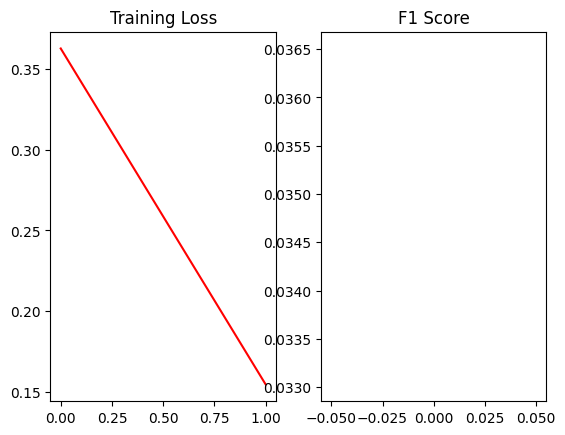

In [29]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(unet_without_connexion.parameters())

## entrainement
unet_without_connexion = train(unet_without_connexion, dataloader, valset, num_epochs=2) ##



Lors de l'entrainement de ce réseau, bien que la loss a diminué, le réseau a mal fonctionné pour le F1-score. Pour l'epoch 1, on a obtenu **nan** celà vient surement des FP, FN,TP,FP. En effet, il a trouvé ```` 0 75278680.0 0.0 4511360 ````
qui correspond à TP = 0;TN = 75278680.0 ; FP = 0.0 et FN =  4511360 . Et comme pour calculer le score, il a besoin de la précision qui est ```` TP/ TP+FP```` ; on voit que 0/0 n'est pas faisable; d'où le nan.

Ca veut dire que sans connexion horizontale entre la partie descendente et la partie montante, le réseau n'est pas interessant en ce qui concerne le coté train. Regardons comment réagit le réseau sur les données de test.

In [30]:
print("\n Évaluation sur le testset...")
testscores_without = test_performance(unet_without_connexion, testset)

print("Résultats de unet_without ")
print("Précision : {:.4f}".format(testscores_without[0]))
print("F1-Score  : {:.4f}".format(testscores_without[2]))


 Évaluation sur le testset...
test_performance: Image  99  /  1124
test_performance: Image  199  /  1124
test_performance: Image  299  /  1124
test_performance: Image  399  /  1124
test_performance: Image  499  /  1124
test_performance: Image  599  /  1124
test_performance: Image  699  /  1124
test_performance: Image  799  /  1124
test_performance: Image  899  /  1124
test_performance: Image  999  /  1124
test_performance: Image  1099  /  1124
321758 239032480.0 18638.0 13841727
Résultats de unet_without 
Précision : 0.9452
F1-Score  : 0.0444


Ici, on voit que même si le réseau a une grande précision, le score n'est pas du tout bon. En regardant de plus près les FN,TP,TN,FP , on se rend compte que le réseau a eu 13841727 de False Negative ce qui contre TP= 321758; on a donc une différence assez grande.

#Question 4


La data augmentation est un processus qui permet d' "augmenter" artificiellement le dataset en faisant des changements mineurs ou pas sur les données déjà existantes. L'intérêt ici est de  permettre au réseau de ne pas faire du sur apprentissage et aussi d'avoir une base de données assez grande.

Dans notre cas ici, vu que nos images sont des fissures sur une route, on peut penser à retourner les images, on aura toujours une fissure sur une route sauf que la fissure sera d'un autre coté.